In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from pathlib import Path
from astropy.io import fits
from galaxy_sidm.mock.residuals import pv_residuals, cube_residuals, cube_noise, has_final_fit
from galaxy_sidm.mock.asymmetry import asymmetry_3d, fit_vsys
from galaxy_sidm.mock.tables import v_flat
from galaxy_sidm.mock.barolo import rings_file

now = Path("/scratch/s4636708/aida/derived/martini")       # production: MARTINI 2, old Hdecompose, kernels x1
test = Path("/scratch/s4636708/aida/_test/v3")             # MARTINI 3, fixed Hdecompose: new/ kernels x1.806, v3check/ kernels x1
wide = Path("/scratch/s4636708/aida/_test/kernel_width")   # kernel test: MARTINI 2, old Hdecompose, kernels x1.806
test_list = Path("/home2/s4636708/tmp/v3_test.txt")
snap_z = {17: 5, 21: 4, 25: 3, 33: 2, 50: 1, 67: 0.5}

def folder(root, model, z, sub):
    return root / f"z{z:g}" / model / f"gal_{sub:06d}"

# the test galaxies: model, redshift, subhalo ID, test folder
galaxies = []
for line in open(test_list):
    model, snap, sub, half, hsm, version = line.split()
    galaxies.append((model, snap_z[int(snap)], int(sub), version))
galaxies

[('CDM', 0.5, 93157, 'new'),
 ('CDM', 0.5, 78273, 'new'),
 ('CDM', 0.5, 81373, 'new'),
 ('CDM', 0.5, 84569, 'new'),
 ('CDM', 0.5, 83331, 'new'),
 ('CDM', 0.5, 72906, 'new'),
 ('CDM', 0.5, 29145, 'new'),
 ('CDM', 0.5, 69646, 'new'),
 ('vSIDM', 0.5, 24064, 'new'),
 ('CDM', 1, 78126, 'new'),
 ('CDM', 1, 46005, 'new'),
 ('CDM', 1, 21353, 'new'),
 ('CDM', 2, 45581, 'new'),
 ('CDM', 2, 35164, 'new'),
 ('CDM', 2, 5789, 'new'),
 ('CDM', 3, 16286, 'new'),
 ('CDM', 3, 13207, 'new'),
 ('CDM', 3, 640, 'new'),
 ('CDM', 4, 4381, 'new'),
 ('CDM', 4, 2028, 'new'),
 ('CDM', 4, 2277, 'new'),
 ('CDM', 5, 2209, 'new'),
 ('CDM', 5, 1296, 'new'),
 ('CDM', 5, 229, 'new'),
 ('CDM', 2, 45581, 'v3check'),
 ('CDM', 2, 35164, 'v3check'),
 ('CDM', 2, 5789, 'v3check'),
 ('CDM', 3, 16286, 'v3check'),
 ('CDM', 3, 13207, 'v3check'),
 ('CDM', 3, 640, 'v3check'),
 ('CDM', 4, 4381, 'v3check'),
 ('CDM', 4, 2028, 'v3check'),
 ('CDM', 4, 2277, 'v3check'),
 ('CDM', 5, 2209, 'v3check'),
 ('CDM', 5, 1296, 'v3check'),
 ('CDM', 

In [ ]:
# MARTINI 3 vs MARTINI 2 with the same kernels (x1), at z = 2 to 5 where the Hdecompose fix changes nothing
rows = []
for model, z, sub, version in galaxies:
    if version != "v3check":
        continue
    old = np.squeeze(fits.getdata(folder(now, model, z, sub) / "cube.fits")).astype(float)
    new = np.squeeze(fits.getdata(folder(test / "v3check", model, z, sub) / "cube.fits")).astype(float)
    diff = np.abs(new - old) / cube_noise(folder(now, model, z, sub))
    rows.append(dict(z=z, subID=sub, largest_difference_sigma=diff.max(),
                     voxels_off_by_more_than_1percent_sigma=int((diff > 0.01).sum()), voxels=diff.size))
pd.DataFrame(rows)

,z,subID,largest_difference_sigma,voxels_off_by_more_than_1percent_sigma,voxels
0,2,45581,1.139732e-04,0,2408704
1,2,35164,1.190054e-05,0,1218816
2,2,5789,7.244550e-05,0,4194304
3,3,16286,3.267977e-14,0,1254400
4,3,13207,3.090516e-14,0,1218816
5,3,640,5.047527e-14,0,1218816
6,4,4381,3.786774e-14,0,4665600
7,4,2028,2.949604e-14,0,4665600
8,4,2277,3.413505e-14,0,1218816
9,5,2209,3.091383e-14,0,1218816


In [4]:
rows = []
for model, z, sub, version in galaxies:
    if version != "new":
        continue
    for run, root in (("now", now), ("wide", wide), ("v3check", test / "v3check"), ("new", test / "new")):
        g = folder(root, model, z, sub)
        if run in ("wide", "v3check") and not g.exists():
            continue
        if not has_final_fit(g):
            print(f"{run}: {model} z = {z:g} {sub} has no final fit")
            continue
        info = json.load(open(g / "info.json"))
        if "pv_emission_end_arcsec" not in info:
            print(f"{run}: {model} z = {z:g} {sub} was fitted with the old ring rule (not in the current sample)")
            continue
        rows.append(dict(model=model, z=z, subID=sub, run=run, M_neutral=info["M_neutral"],
                         rings=info["nradii"], hole_rings=len(info.get("hole_rings_arcsec") or []),
                         end=max(v for v in info["pv_emission_end_arcsec"] if v is not None),
                         v_flat=v_flat(g / "bbarolo"), sigma=info["sigma"], VSYS=fit_vsys(g / "bbarolo"),
                         pv_res1=pv_residuals(g)[0], cube_res1=cube_residuals(g)[0], A_sq=asymmetry_3d(g).A_sq))
table = pd.DataFrame(rows)
table.round(3)

now: CDM z = 5 2209 was fitted with the old ring rule (not in the current sample)
now: CDM z = 5 1296 was fitted with the old ring rule (not in the current sample)
now: CDM z = 5 229 was fitted with the old ring rule (not in the current sample)


,model,z,subID,run,M_neutral,rings,hole_rings,end,v_flat,sigma,VSYS,pv_res1,cube_res1,A_sq
0,CDM,0.5,93157,now,2.201793e+09,9,0,275.0,110.767,13.371,339.202,17.824,20.323,0.107
1,CDM,0.5,93157,wide,2.201793e+09,9,0,275.0,111.247,13.597,339.722,17.850,19.819,0.103
2,CDM,0.5,93157,new,2.093366e+09,9,0,275.0,111.667,13.849,339.584,17.511,19.950,0.103
3,CDM,0.5,78273,now,1.272003e+10,26,0,770.0,180.282,12.221,342.298,26.452,24.896,0.154
4,CDM,0.5,78273,wide,1.272003e+10,26,0,770.0,181.224,11.742,342.848,28.125,25.637,0.148
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,CDM,5.0,2209,new,1.456307e+10,7,0,215.0,NaN,22.178,329.624,21.089,12.407,0.152
61,CDM,5.0,1296,v3check,2.724599e+10,4,0,100.0,NaN,33.361,456.446,21.799,11.018,0.039
62,CDM,5.0,1296,new,2.724599e+10,4,0,100.0,NaN,36.959,456.081,21.020,10.715,0.038
63,CDM,5.0,229,v3check,3.496111e+10,18,5,545.0,NaN,43.448,438.577,35.676,12.083,0.162


---
one galaxy at a time

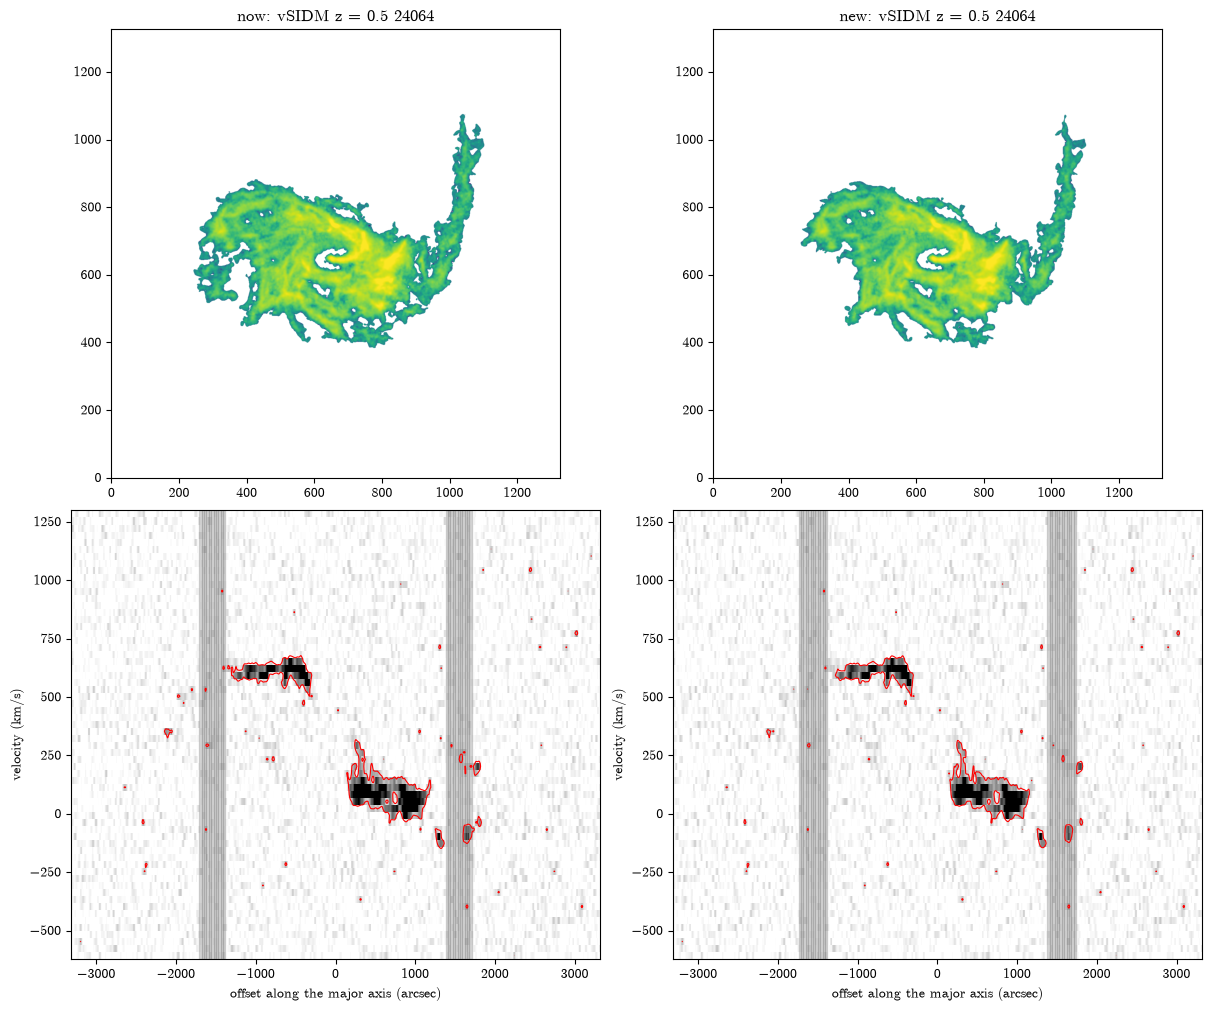

In [7]:
# 3-ring fit
sub_id = 24064
model, z = next((m, zz) for m, zz, s, v in galaxies if s == sub_id)

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
for col, (run, root) in enumerate((("now", now), ("new", test / "new"))):
    g = folder(root, model, z, sub_id)
    info = json.load(open(g / "info.json"))
    mom0 = np.squeeze(fits.getdata(g / "bbarolo_3rings" / "maps" / "MOCK_0mom.fits"))
    pv_file = g / "bbarolo_3rings" / "pvs" / "MOCK_pv_a.fits"
    pv = np.nan_to_num(np.squeeze(fits.getdata(pv_file)))
    hp = fits.getheader(pv_file)
    offset = (np.arange(hp["NAXIS1"]) + 1 - hp["CRPIX1"]) * hp["CDELT1"] * 3600                  # deg -> arcsec
    velocity = (hp["CRVAL2"] + (np.arange(hp["NAXIS2"]) + 1 - hp["CRPIX2"]) * hp["CDELT2"]) / 1000   # m/s -> km/s
    if col == 0:   # colour scales from the production galaxy, used for both
        mom0_max = np.nanpercentile(mom0, 99)
        pv_max = np.percentile(pv, 99.5)
    axes[0, col].imshow(mom0, origin="lower", cmap="viridis", norm=LogNorm(vmin=mom0_max / 1000, vmax=mom0_max))
    axes[0, col].set_title(f"{run}: {model} z = {z:g} {sub_id}")
    axes[1, col].pcolormesh(offset, velocity, pv, cmap="Greys", vmin=0, vmax=pv_max)
    axes[1, col].contour(offset, velocity, pv / cube_noise(g), levels=[3], colors="red", linewidths=0.8)
    w = info.get("ring_width_arcsec")
    for r in info.get("hole_rings_arcsec") or []:
        axes[1, col].axvspan(r - w / 2, r + w / 2, color="grey", alpha=0.3)
        axes[1, col].axvspan(-r - w / 2, -r + w / 2, color="grey", alpha=0.3)
    axes[1, col].set_xlabel("offset along the major axis (arcsec)")
    axes[1, col].set_ylabel("velocity (km/s)")
plt.show()

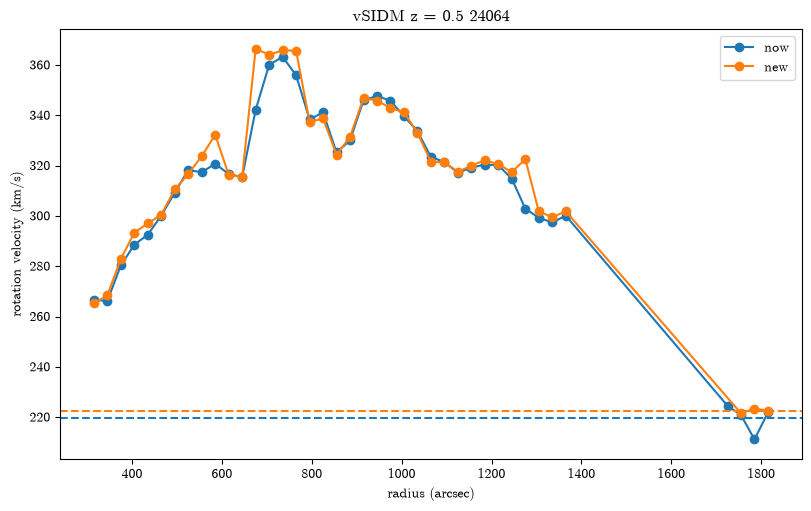

In [8]:
# the final fit
sub_id = 24064
model, z = next((m, zz) for m, zz, s, v in galaxies if s == sub_id)

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for run, root, colour in (("now", now, "C0"), ("wide", wide, "C2"), ("v3check", test / "v3check", "C3"),
                          ("new", test / "new", "C1")):
    g = folder(root, model, z, sub_id)
    if not has_final_fit(g):
        if run not in ("wide", "v3check"):
            print(f"{run}: no final fit")
        continue
    if "pv_emission_end_arcsec" not in json.load(open(g / "info.json")):
        print(f"{run}: fitted with the old ring rule, not shown")
        continue
    rings = np.loadtxt(rings_file(g / "bbarolo"), comments="#", ndmin=2)
    ax.plot(rings[:, 1], rings[:, 2], "o-", color=colour, label=run)   # columns: RAD(arcs), VROT(km/s)
    vf = v_flat(g / "bbarolo")
    if np.isfinite(vf):
        ax.axhline(vf, color=colour, ls="--")
ax.set_xlabel("radius (arcsec)")
ax.set_ylabel("rotation velocity (km/s)")
ax.set_title(f"{model} z = {z:g} {sub_id}")
ax.legend()
plt.show()